In [1]:
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import numpy as np
import scipy.stats as stats
from scipy.stats import kurtosis
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
df = pd.read_csv('data/car data.csv')

df_cols = df.columns
df['Selling_Price'] = df['Selling_Price'] * 100000
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,335000.0,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,475000.0,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,725000.0,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,285000.0,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,460000.0,6.87,42450,Diesel,Dealer,Manual,0


In [3]:
df1 = pd.read_csv('data/Car details v3.csv')

df1_cols = df1.columns
df1.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [4]:
df2 = pd.read_csv('data/Car details v4.csv')
#print(df2.info())
df2_cols = df2.columns
df2.head()

,Make,Model,Price,Year,Kilometer,Fuel Type,Transmission,Location,Color,Owner,Seller Type,Engine,Max Power,Max Torque,Drivetrain,Length,Width,Height,Seating Capacity,Fuel Tank Capacity
0,Honda,Amaze 1.2 VX i-VTEC,505000,2017,87150,Petrol,Manual,Pune,Grey,First,Corporate,1198 cc,87 bhp @ 6000 rpm,109 Nm @ 4500 rpm,FWD,3990.0,1680.0,1505.0,5.0,35.0
1,Maruti Suzuki,Swift DZire VDI,450000,2014,75000,Diesel,Manual,Ludhiana,White,Second,Individual,1248 cc,74 bhp @ 4000 rpm,190 Nm @ 2000 rpm,FWD,3995.0,1695.0,1555.0,5.0,42.0
2,Hyundai,i10 Magna 1.2 Kappa2,220000,2011,67000,Petrol,Manual,Lucknow,Maroon,First,Individual,1197 cc,79 bhp @ 6000 rpm,112.7619 Nm @ 4000 rpm,FWD,3585.0,1595.0,1550.0,5.0,35.0
3,Toyota,Glanza G,799000,2019,37500,Petrol,Manual,Mangalore,Red,First,Individual,1197 cc,82 bhp @ 6000 rpm,113 Nm @ 4200 rpm,FWD,3995.0,1745.0,1510.0,5.0,37.0
4,Toyota,Innova 2.4 VX 7 STR [2016-2020],1950000,2018,69000,Diesel,Manual,Mumbai,Grey,First,Individual,2393 cc,148 bhp @ 3400 rpm,343 Nm @ 1400 rpm,RWD,4735.0,1830.0,1795.0,7.0,55.0


In [5]:
df3 = pd.read_csv('data\CAR DETAILS FROM CAR DEKHO.csv')
# print(df3.info())
df3_cols = df3.columns
df3.head()

<>:1: SyntaxWarning: "\C" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\C"? A raw string is also an option.
<>:1: SyntaxWarning: "\C" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\C"? A raw string is also an option.
C:\Users\borde\AppData\Local\Temp\ipykernel_22448\2689844547.py:1: SyntaxWarning: "\C" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\C"? A raw string is also an option.
  df3 = pd.read_csv('data\CAR DETAILS FROM CAR DEKHO.csv')


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


## Cleaning/Pre-processing

-  check nulls .isna() for all columns
-  plot: year, price, kms, owner, correlation matrix
-  scale into thousands kms, price
-  standard scale year?
-  encode seller type, transmission, owner, fuel



In [6]:
collists = [ df_cols, df1_cols, df2_cols, df3_cols]
dfs = ['df', 'df1', 'df2', 'df3']
collists = [i.tolist() for i in collists]

[print(i) for i in collists]

coldicts = {df_name: cols for df_name, cols in zip(dfs, collists)}

print(coldicts)



['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner']
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage', 'engine', 'max_power', 'torque', 'seats']
['Make', 'Model', 'Price', 'Year', 'Kilometer', 'Fuel Type', 'Transmission', 'Location', 'Color', 'Owner', 'Seller Type', 'Engine', 'Max Power', 'Max Torque', 'Drivetrain', 'Length', 'Width', 'Height', 'Seating Capacity', 'Fuel Tank Capacity']
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']
{'df': ['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner'], 'df1': ['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage', 'engine', 'max_power', 'torque', 'seats'], 'df2': ['Make', 'Model', 'Price', 'Year', 'Kilometer', 'Fuel Type', 'Transmission', 'Location', 'Color', 

In [7]:
newcols = {
    'make':['Make'],
    'name': ['Car_Name', 'Model'],
    'year': ['Year'],
    'price': ['Selling_Price', 'selling_price', 'Price'],
    'km': ['Kms_Driven', 'km_driven', 'Kilometer'],
    'fuel': ['Fuel_Type', 'Fuel Type'],
    'seller': ['Seller_Type', 'seller_type', 'Seller Type'],
    'transmission': ['Transmission'],
    'owner': ['Owner'],
    'engine': ['Engine'],
    'max_power': ['Max Power'],
    'max_torque': ['Max Torque'],
    'seating': ['Seating Capacity'],
    'tank_capacity': ['Fuel Tank Capacity'],
    'km_per_l': ['mileage']
}

cols = {
    'df': ['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner'],
    'df1': ['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage', 'engine', 'max_power', 'torque', 'seats'],
    'df2': ['Make', 'Model', 'Price', 'Year', 'Kilometer', 'Fuel Type', 'Transmission', 'Location', 'Color', 'Owner', 'Seller Type', 'Engine', 'Max Power', 'Max Torque', 'Drivetrain', 'Length', 'Width', 'Height', 'Seating Capacity', 'Fuel Tank Capacity'],
    'df3': ['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']
}

# Invert: old name -> new name
lookup = {old: new for new, olds in newcols.items() for old in olds}

# Nested comprehension: for each df, rename each column if it's in the lookup
renamed = {
    df_name: [lookup.get(col, col) for col in columns]
    for df_name, columns in cols.items()
}


dfs = {'df': df, 'df1': df1, 'df2': df2, 'df3': df3}
for name, d in dfs.items():
    d.rename(columns=lookup, inplace=True)


In [8]:
# standardise columns
owner_map = {'First': 1, 'Second': 12, 'Third': 3}

for name, d in dfs.items():
    if pd.api.types.is_numeric_dtype(d['owner']):
        d['owner'] = d['owner'] + 1
    else:
        d['owner'] = (
            d['owner'].str.replace('Owner', '', regex=False)
            .str.strip()
            .map(owner_map)
        )
    d['owner'] = d['owner'].astype('Int64')

In [9]:
# concat all dfs 
combined = pd.concat(dfs, names=['source', None]).reset_index(level='source').reset_index(drop=True)

In [10]:
# Scale price and km columns

combined[['price', 'km']] = combined[['price', 'km']] / 1000

## Create make column and populate from name column

In [11]:
first_word = combined['name'].str.strip().str.split().str[0]

combined['make'] = (
    combined['make']
    .fillna(first_word)
    .str.strip()
    .str.title()
)

In [12]:
#print(combined['make'].isna().sum())
#print(combined['make'].nunique())
#print(combined['make'].value_counts())
#print(combined.groupby('source')['make'].nunique())
#print(combined.loc[combined['source'] == 'df', 'make'].value_counts().head(20))


In [ ]:
model_to_make = {
    # Honda
    'City': 'Honda', 'Brio': 'Honda', 'Amaze': 'Honda', 'Jazz': 'Honda',
    # Toyota
    'Corolla': 'Toyota', 'Fortuner': 'Toyota', 'Etios': 'Toyota', 'Innova': 'Toyota',
    # Hyundai
    'Verna': 'Hyundai', 'I20': 'Hyundai', 'I10': 'Hyundai', 'Grand': 'Hyundai',
    'Eon': 'Hyundai', 'Xcent': 'Hyundai', 'Creta': 'Hyundai', 'Elantra': 'Hyundai',
    # Maruti
    'Ciaz': 'Maruti', 'Sx4': 'Maruti', 'Alto': 'Maruti', 'Ertiga': 'Maruti',
    'Swift': 'Maruti', 'Ritz': 'Maruti', 'Wagon': 'Maruti', 'Dzire': 'Maruti',
    'Vitara': 'Maruti', 'Ignis': 'Maruti', 'S': 'Maruti',
}

mask = combined['source'] == 'df'
combined.loc[mask, 'make'] = combined.loc[mask, 'make'].replace(model_to_make)

#print(combined.loc[mask, 'make'].value_counts().to_string())

In [17]:
combined.head()

,source,name,year,price,Present_Price,km,fuel,seller,transmission,owner,...,make,Location,Color,max_torque,Drivetrain,Length,Width,Height,seating,tank_capacity
0,df,ritz,2014,335.0,5.59,27.00,Petrol,Dealer,Manual,1,...,Maruti,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,df,sx4,2013,475.0,9.54,43.00,Diesel,Dealer,Manual,1,...,Maruti,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,df,ciaz,2017,725.0,9.85,6.90,Petrol,Dealer,Manual,1,...,Maruti,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,df,wagon r,2011,285.0,4.15,5.20,Petrol,Dealer,Manual,1,...,Maruti,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,df,swift,2014,460.0,6.87,42.45,Diesel,Dealer,Manual,1,...,Maruti,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Duplicates

In [18]:
# Checks to confirm actual dupes

cols = ['make', 'name', 'year', 'km', 'price']

dup_mask = combined.duplicated(subset=cols, keep=False)   # keep=False marks every row in a group
print(combined[dup_mask].groupby('source').size())

groups = combined[dup_mask].groupby(cols)['source'].agg(['nunique', 'size'])
print("groups spanning more than one source:", (groups['nunique'] > 1).sum())
print("groups within a single source:       ", (groups['nunique'] == 1).sum())

source
df        6
df1    1899
df2      10
df3    1351
dtype: int64
groups spanning more than one source: 59
groups within a single source:        1161


In [19]:
more = ['make', 'name', 'year', 'km', 'price', 'fuel', 'seller', 'transmission', 'owner']
more = [c for c in more if c in combined.columns]

print(combined.duplicated(subset=cols).sum())    # 2046
print(combined.duplicated(subset=more).sum())    # compare

2046
2022


In [20]:
# 1.  fix 
mask = combined['source'] == 'df'
combined.loc[mask, 'make'] = combined.loc[mask, 'make'].replace(model_to_make)

bike_makes = ['Bajaj', 'Royal', 'Hero', 'Yamaha', 'Tvs', 'Ktm', 'Activa', 'Hyosung', 'Um']
combined = combined[~(mask & combined['make'].isin(bike_makes))].copy()

# 2. dedupe on the longer column list
more = ['make', 'name', 'year', 'km', 'price', 'fuel', 'seller', 'transmission', 'owner']
more = [c for c in more if c in combined.columns]

print("duplicates:", combined.duplicated(subset=more).sum())

before = len(combined)
combined = combined.drop_duplicates(subset=more, keep='first').reset_index(drop=True)
print(f'Dropped {before - len(combined)} rows, {len(combined)} remain')

duplicates: 2022
Dropped 2022 rows, 12724 remain


## Missing Values

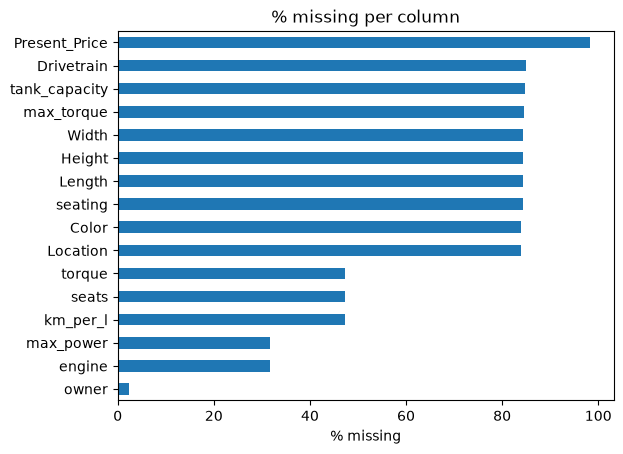

In [21]:
# Check missing values

missing_pct = round(combined.isnull().mean()*100, 1)
missing_pct[missing_pct > 0].sort_values(ascending=False)

missing_pct[missing_pct > 0].sort_values().plot(kind="barh", title="% missing per column")
plt.xlabel('% missing')
plt.show()

In [23]:
# drop columns with large amount of NaN's

clean = combined.drop(columns=['Present_Price', 'Location','Color','max_torque', 'Drivetrain', 'Length', 'Width', 'Height', 'seating', 'tank_capacity', 'km_per_l','engine','max_power', 'torque', 'seats' ])
clean.head()

,source,name,year,price,km,fuel,seller,transmission,owner,make
0,df,ritz,2014,335.0,27.00,Petrol,Dealer,Manual,1,Maruti
1,df,sx4,2013,475.0,43.00,Diesel,Dealer,Manual,1,Maruti
2,df,ciaz,2017,725.0,6.90,Petrol,Dealer,Manual,1,Maruti
3,df,wagon r,2011,285.0,5.20,Petrol,Dealer,Manual,1,Maruti
4,df,swift,2014,460.0,42.45,Diesel,Dealer,Manual,1,Maruti


## Outliers

In [24]:
print("Mean year:  ", round(clean["year"].mean(), 2))
print("Median year:", clean["year"].median())

Mean year:   2013.78
Median year: 2014.0


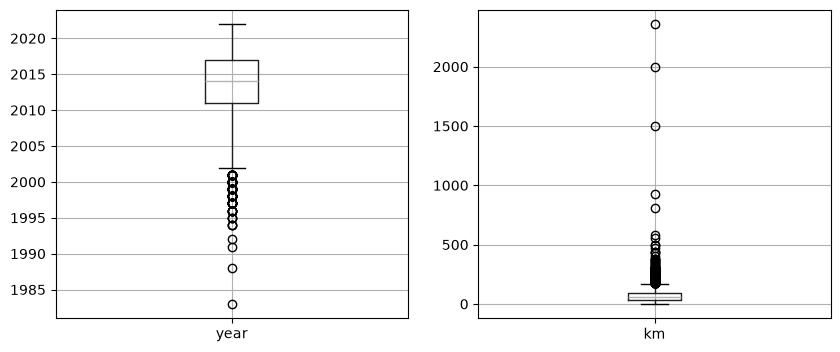

In [25]:
# Plot distribution of numerical cells

fig, axes = plt.subplots(1, 2, figsize=(10,4))
clean.boxplot(column="year", ax=axes[0])
clean.boxplot(column="km", ax=axes[1])
plt.show()

# drop outliers --> year < 2000 ; km > 550

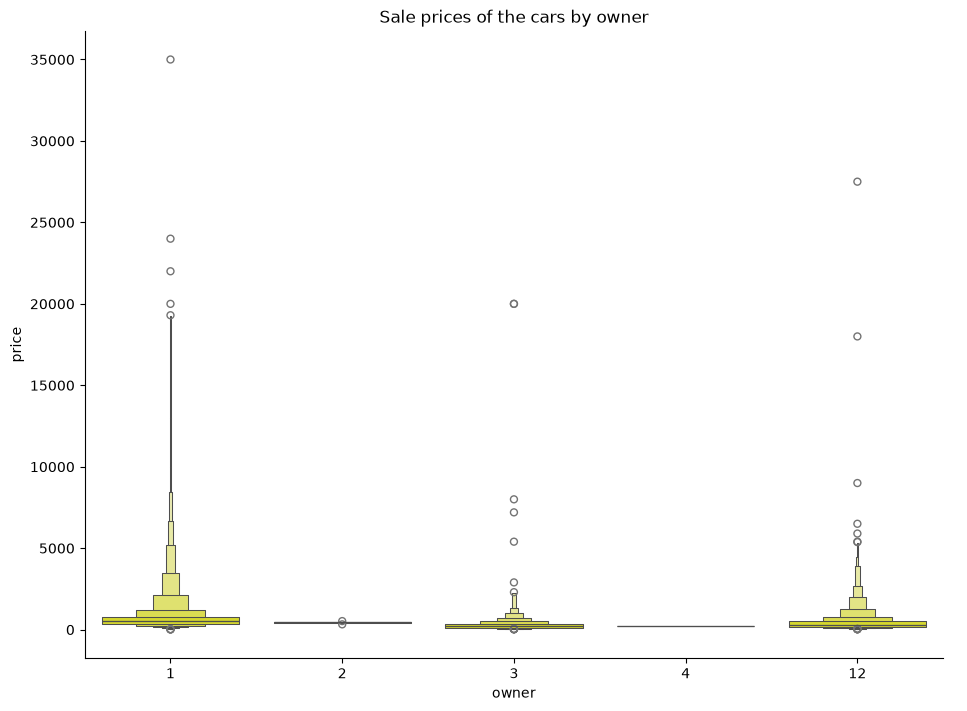

In [26]:
sns.catplot(x = clean["owner"],
            y = clean["price"],
            kind = "boxen",
            height = 7,
            aspect = 1.37,
            color = "#F0F312",
            data = df).set(title = "Sale prices of the cars by owner");

In [27]:
# Check outliers in numerical colums: year and km

for y in (1995, 2000):
    print(f'year < {y}:', (combined['year'] < y).sum())
for k in (550, 900, 1000):
    print(f'km > {k}:', (combined['km'] > k).sum())
print('total rows:', len(combined))

year < 1995: 7
year < 2000: 75
km > 550: 7
km > 900: 4
km > 1000: 3
total rows: 12724


Dropped 82 rows, 12642 remain


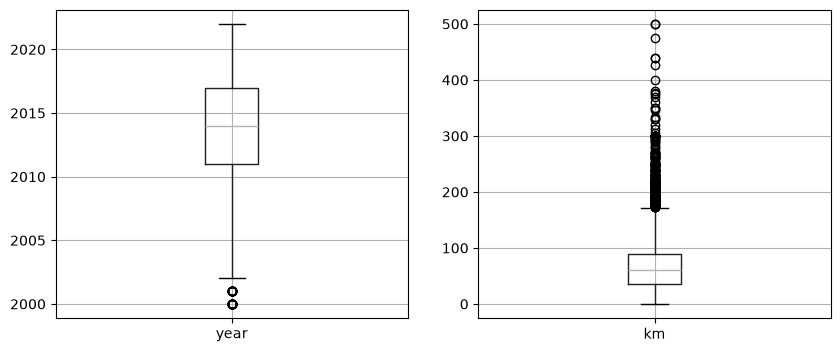

In [28]:
# drop outliers in year and km and re-check box plots

before = len(combined)
clean = clean[(clean['year'] >= 2000) & (clean['km'] <= 550)].copy()
print(f'Dropped {before - len(clean)} rows, {len(clean)} remain') 

#combined[['year', 'km']].isna().sum()


fig, axes = plt.subplots(1, 2, figsize=(10,4))
clean.boxplot(column="year", ax=axes[0])
clean.boxplot(column="km", ax=axes[1])
plt.show()

In [29]:
cols = ["year", "km"]

standard = StandardScaler().fit_transform(clean[cols])

comparison = pd.DataFrame({
    "year": clean["year"],
    "year_standard": standard[:, 0],
    "km": clean["km"],
    "km_standard": standard[:, 1],
}).round(2)
comparison.head()

,year,year_standard,km,km_standard
0,2014,0.03,27.00,-0.90
1,2013,-0.22,43.00,-0.55
2,2017,0.78,6.90,-1.34
3,2011,-0.72,5.20,-1.38
4,2014,0.03,42.45,-0.56


## Correlation Matrix

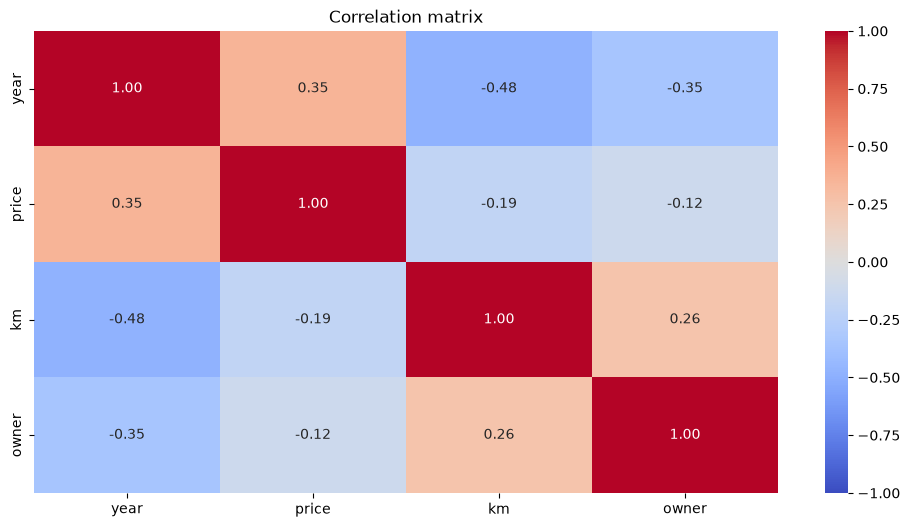

price    1.000000
year     0.352260
owner   -0.117660
km      -0.190001
Name: price, dtype: float64

In [31]:
corr = clean.corr(numeric_only=True)
plt.figure(figsize=(12,6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.show()

corr["price"].sort_values(ascending=False)

## Encoding
- Bianary Encoding
- One-Hot Encoding

In [32]:
# One-Hot Encoding

# check columns for One-hot encoding

clean['transmission'].unique() #2
clean['seller'].unique() #5
clean['fuel'].unique() #9

clean['seller'].value_counts(dropna=False)

clean['fuel'] = clean['fuel'].replace({'CNG + CNG': 'CNG'})
clean = clean[~clean['fuel'].isin(['Petrol + CNG', 'Petrol + LPG'])].copy()

In [33]:
# One-Hot Encoding

# fuel
fuel_dummies = pd.get_dummies(clean["fuel"], prefix="fuel", dtype=int, drop_first=True)  # drop first column for simple linear regression to break colinearlity between dummy columns
#clean = pd.concat([clean.drop(columns=['fuel']), fuel_dummies], axis=1)
pd.concat([clean["fuel"], fuel_dummies], axis=1).head()
clean = pd.concat([clean, fuel_dummies], axis=1)

#seller
seller_dummies = pd.get_dummies(clean["seller"], prefix="seller", dtype=int)
pd.concat([clean["seller"], seller_dummies], axis=1).head()
clean = pd.concat([clean, seller_dummies], axis=1)

In [34]:
# Binany Encoding
clean["transmiss_encoded"] = clean["transmission"].map({"Manual": 0, "Automatic": 1})
clean[["transmission", "transmiss_encoded"]].head()

,transmission,transmiss_encoded
0,Manual,0
1,Manual,0
2,Manual,0
3,Manual,0
4,Manual,0


In [ ]:
# Plot numeric features individually

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, col in zip(axes, ['year', 'km']):
    ax.scatter(Xs_train[col], ys_train, alpha=0.3, s=10)
    ax.set_xlabel(col)
    ax.set_ylabel("price (£k)")

plt.tight_layout()
plt.show()

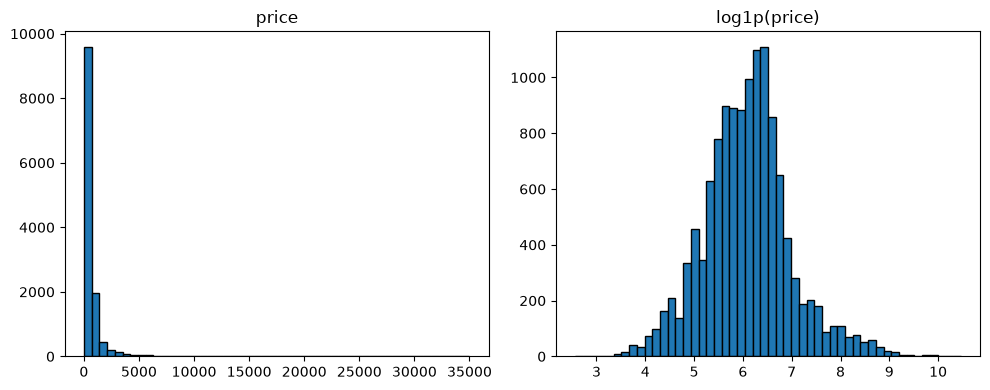

In [37]:
# Distribution of price

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(clean['price'], bins=50, edgecolor='black')
axes[0].set_title("price")

axes[1].hist(np.log1p(clean['price']), bins=50, edgecolor='black')
axes[1].set_title("log1p(price)")

plt.tight_layout()
plt.show()

# convert price to log price
clean['log_price'] = np.log1p(clean['price'])

In [38]:
# Price Kurtosis
k_raw = kurtosis(clean['price'].dropna())                  # excess kurtosis (normal = 0)
k_log = kurtosis(np.log1p(clean['price']).dropna())

print(f"Excess kurtosis, price:        {k_raw:.2f}")
print(f"Excess kurtosis, log1p(price): {k_log:.2f}")


Excess kurtosis, price:        153.91
Excess kurtosis, log1p(price): 1.08


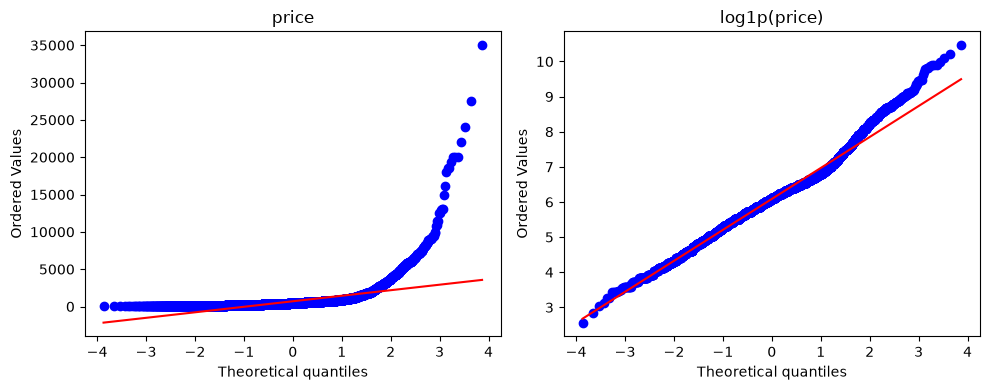

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
stats.probplot(clean['price'].dropna(), dist="norm", plot=axes[0]); axes[0].set_title("price")
stats.probplot(np.log1p(clean['price']).dropna(), dist="norm", plot=axes[1]); axes[1].set_title("log1p(price)")
plt.tight_layout(); plt.show()

In [40]:
y = clean['log_price']
X = clean[['year', 'km', 'fuel_Diesel', 'fuel_Electric', 'fuel_Hybrid', 'fuel_LPG',
           'fuel_Petrol', 'seller_Commercial Registration', 'seller_Corporate',
           'seller_Dealer', 'seller_Trustmark Dealer', 'transmiss_encoded']]

Xs_train, Xs_test, ys_train, ys_test = train_test_split(X, y, test_size=0.2, random_state=42)

simple_model = LinearRegression().fit(Xs_train, ys_train)
y_pred_log = simple_model.predict(Xs_test)


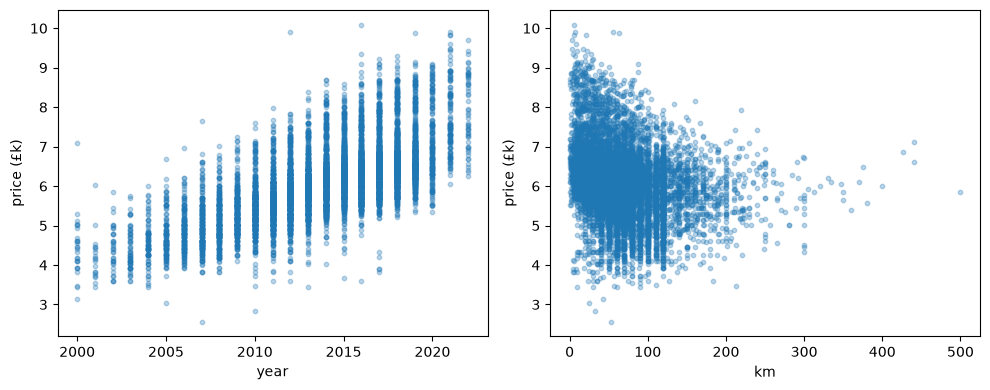

In [41]:
# Plot numeric features individually

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, col in zip(axes, ['year', 'km']):
    ax.scatter(Xs_train[col], ys_train, alpha=0.3, s=10)
    ax.set_xlabel(col)
    ax.set_ylabel("price (£k)")

plt.tight_layout()
plt.show()

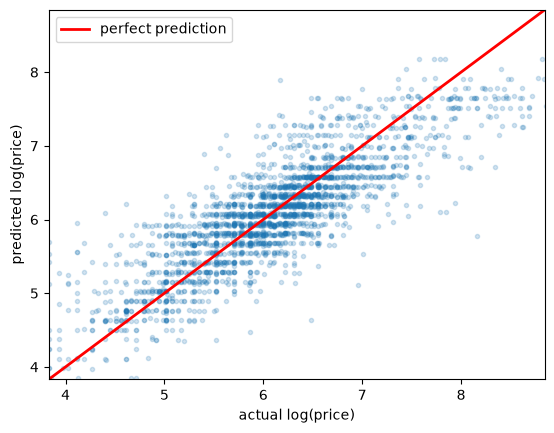

Train R2 (log)   0.7098708700557073
Test R2 (log)    0.6940562692443688
Test R2 (price)  0.24966047297293448
MAE (£k)         309.78475533281846
RMSE (£k)        1228.1151522383616


In [42]:

# Plot: predicted vs actual (log scale)
lo, hi = np.percentile(ys_test, [0.5, 99.5])

plt.scatter(ys_test, y_pred_log, alpha=0.2, s=9)
plt.plot([lo, hi], [lo, hi], "r", lw=2, label="perfect prediction")
plt.xlim(lo, hi); plt.ylim(lo, hi)
plt.xlabel("actual log(price)"); plt.ylabel("predicted log(price)")
plt.legend(); plt.show()

# Metrics
pred, actual = np.expm1(y_pred_log), np.expm1(ys_test)

print("Train R2 (log)  ", simple_model.score(Xs_train, ys_train))
print("Test R2 (log)   ", r2_score(ys_test, y_pred_log))
print("Test R2 (price) ", r2_score(actual, pred))
print("MAE (£k)        ", mean_absolute_error(actual, pred))
print("RMSE (£k)       ", np.sqrt(mean_squared_error(actual, pred)))

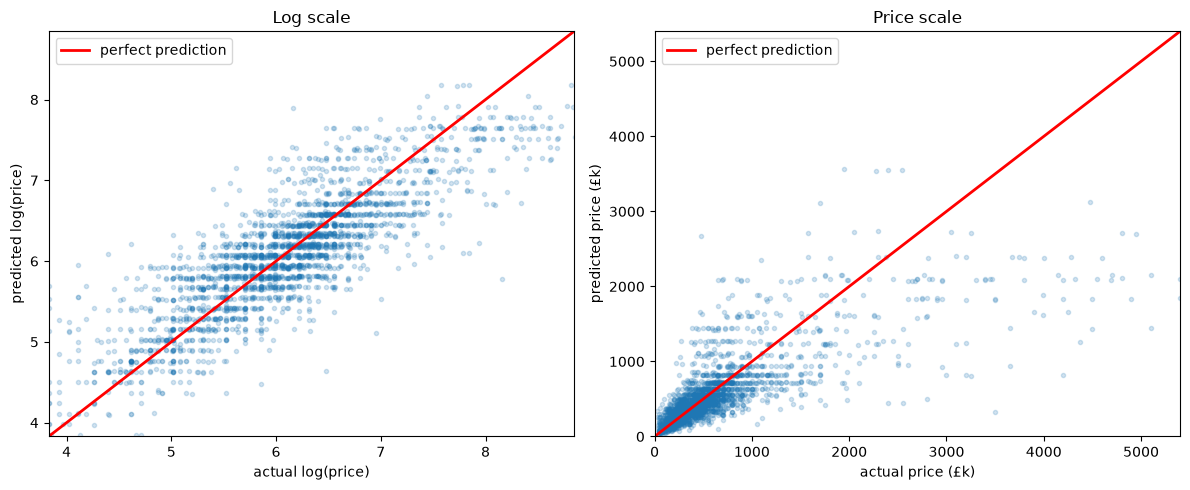

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Left: log scale (what the model was fitted on)
lo, hi = np.percentile(ys_test, [0.5, 99.5])
axes[0].scatter(ys_test, y_pred_log, alpha=0.2, s=9)
axes[0].plot([lo, hi], [lo, hi], "r", lw=2, label="perfect prediction")
axes[0].set_xlim(lo, hi); axes[0].set_ylim(lo, hi)
axes[0].set_xlabel("actual log(price)")
axes[0].set_ylabel("predicted log(price)")
axes[0].set_title("Log scale")
axes[0].legend()

# Right: price scale (£k)
pred, actual = np.expm1(y_pred_log), np.expm1(ys_test)
cap = np.percentile(actual, 99)
axes[1].scatter(actual, pred, alpha=0.2, s=9)
axes[1].plot([0, cap], [0, cap], "r", lw=2, label="perfect prediction")
axes[1].set_xlim(0, cap); axes[1].set_ylim(0, cap)
axes[1].set_xlabel("actual price (£k)")
axes[1].set_ylabel("predicted price (£k)")
axes[1].set_title("Price scale")
axes[1].legend()

plt.tight_layout()
plt.show()

## Ridge & Lasso (with hyperparm tuning and cross validation built in)

In [ ]:
# Run

alphas = np.logspace(-4, 2, 50)

# numeric columns only for the linear models (make is a category)
Xl_train, Xl_test = Xs_train[num_cols], Xs_test[num_cols]

# fitted pipelines
lin_pipe   = make_pipeline(StandardScaler(), LinearRegression()).fit(Xl_train, ys_train)
ridge_pipe = make_pipeline(StandardScaler(), RidgeCV(alphas=alphas, cv=5)).fit(Xl_train, ys_train)
lasso_pipe = make_pipeline(StandardScaler(), LassoCV(alphas=alphas, cv=5, max_iter=10000, random_state=42)).fit(Xl_train, ys_train)

# the CV estimator inside each pipeline (for alpha_, coef_, mse_path_)
lin_est   = lin_pipe[-1]
ridge_est = ridge_pipe[-1]
lasso_est = lasso_pipe[-1]

# predictions on the test set (log scale), saved once and reused for plots and metrics
y_pred_log_lin   = lin_pipe.predict(Xl_test)
y_pred_log_ridge = ridge_pipe.predict(Xl_test)
y_pred_log_lasso = lasso_pipe.predict(Xl_test)

preds_log = {
    "Linear": y_pred_log_lin,
    "Ridge":  y_pred_log_ridge,
    "Lasso":  y_pred_log_lasso,
}
y_true_log = np.ravel(ys_test)

print("Ridge alpha:", ridge_est.alpha_)
print("Lasso alpha:", lasso_est.alpha_)

Ridge alpha: 4.498432668969444
Lasso alpha: 0.00017575106248547912


In [ ]:
# Errors

models = {
    "Linear": (lin_pipe,   Xl_train, Xl_test),
    "Ridge":  (ridge_pipe, Xl_train, Xl_test),
    "Lasso":  (lasso_pipe, Xl_train, Xl_test),
    "HGB":    (hgb,        Xs_train, Xs_test),   # only HGB sees `make`
}

y_true_log = np.ravel(ys_test)
actual = np.expm1(y_true_log)

rows = []
for name, (m, Xtr_, Xte_) in models.items():
    p_log = np.ravel(m.predict(Xte_))
    pred = np.expm1(p_log)
    rows.append({
        "Model":           name,
        "Train R2 (log)":  m.score(Xtr_, ys_train),
        "Test R2 (log)":   r2_score(y_true_log, p_log),
        "Test R2 (price)": r2_score(actual, pred),
        "MAE (log)":       mean_absolute_error(y_true_log, p_log),
        "RMSE (log)":      np.sqrt(mean_squared_error(y_true_log, p_log)),
        "MAE (£k)":        mean_absolute_error(actual, pred),
        "RMSE (£k)":       np.sqrt(mean_squared_error(actual, pred)),
        "Median % error":  np.median(np.abs(pred - actual) / actual) * 100,
    })

metrics = pd.DataFrame(rows).set_index("Model").round(3)
print(metrics)

        Train R2 (log)  Test R2 (log)  Test R2 (price)  MAE (log)  RMSE (log)  \
Model                                                                           
Linear           0.710          0.694            0.250      0.362       0.493   
Ridge            0.710          0.694            0.250      0.362       0.493   
Lasso            0.710          0.694            0.250      0.362       0.493   
HGB              0.866          0.814            0.463      0.278       0.384   

        MAE (£k)  RMSE (£k)  Median % error  
Model                                        
Linear   309.785   1228.115          26.580  
Ridge    309.789   1228.197          26.573  
Lasso    309.797   1228.211          26.604  
HGB      227.220   1039.377          21.509  


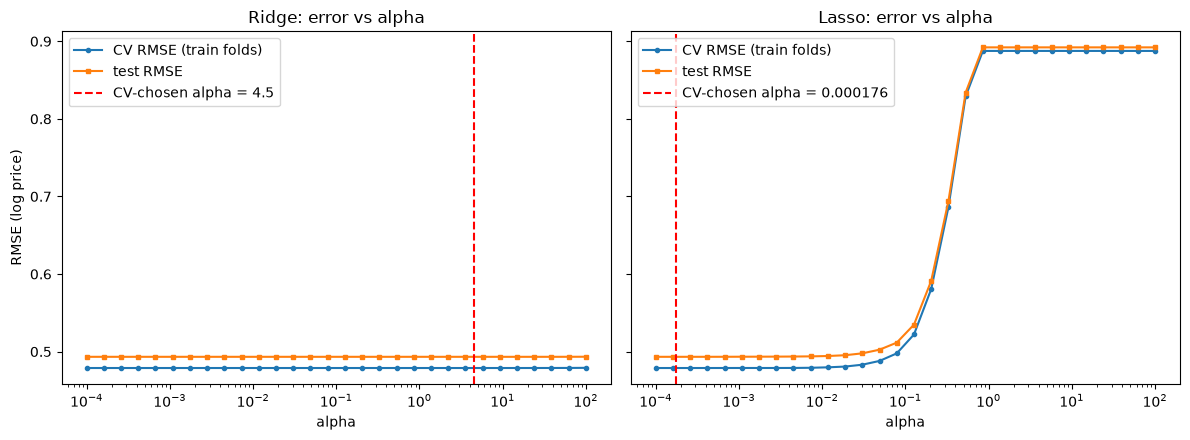

In [ ]:
# Plot Error as Function of Alpha, e.g. Hyperparm tuning

from sklearn.model_selection import cross_val_score

alphas = np.logspace(-4, 2, 30)
scaler = StandardScaler().fit(Xl_train)
Xtr, Xte = scaler.transform(Xl_train), scaler.transform(Xl_test)

def error_curve(Model):
    cv_rmse, test_rmse = [], []
    for a in alphas:
        m = Model(alpha=a, max_iter=10000) if Model is Lasso else Model(alpha=a)
        cv = -cross_val_score(m, Xtr, ys_train, cv=5,
                              scoring="neg_root_mean_squared_error").mean()
        m.fit(Xtr, ys_train)
        cv_rmse.append(cv)
        test_rmse.append(np.sqrt(mean_squared_error(ys_test, m.predict(Xte))))
    return np.array(cv_rmse), np.array(test_rmse)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

for ax, (name, Model, best) in zip(axes, [("Ridge", Ridge, ridge[-1].alpha_),
                                         ("Lasso", Lasso, lasso[-1].alpha_)]):
    cv_rmse, test_rmse = error_curve(Model)
    ax.plot(alphas, cv_rmse, "o-", ms=3, label="CV RMSE (train folds)")
    ax.plot(alphas, test_rmse, "s-", ms=3, label="test RMSE")
    ax.axvline(best, color="r", ls="--", label=f"CV-chosen alpha = {best:.3g}")
    ax.set_xscale("log")
    ax.set_xlabel("alpha"); ax.set_title(f"{name}: error vs alpha")
    ax.legend()
axes[0].set_ylabel("RMSE (log price)")

plt.tight_layout(); plt.show()

In [62]:
coefs = pd.DataFrame({
      "Linear": lin_est.coef_,
      "Ridge":  ridge_est.coef_,
      "Lasso":  lasso_est.coef_,
  }, index=Xl_train.columns).round(3)

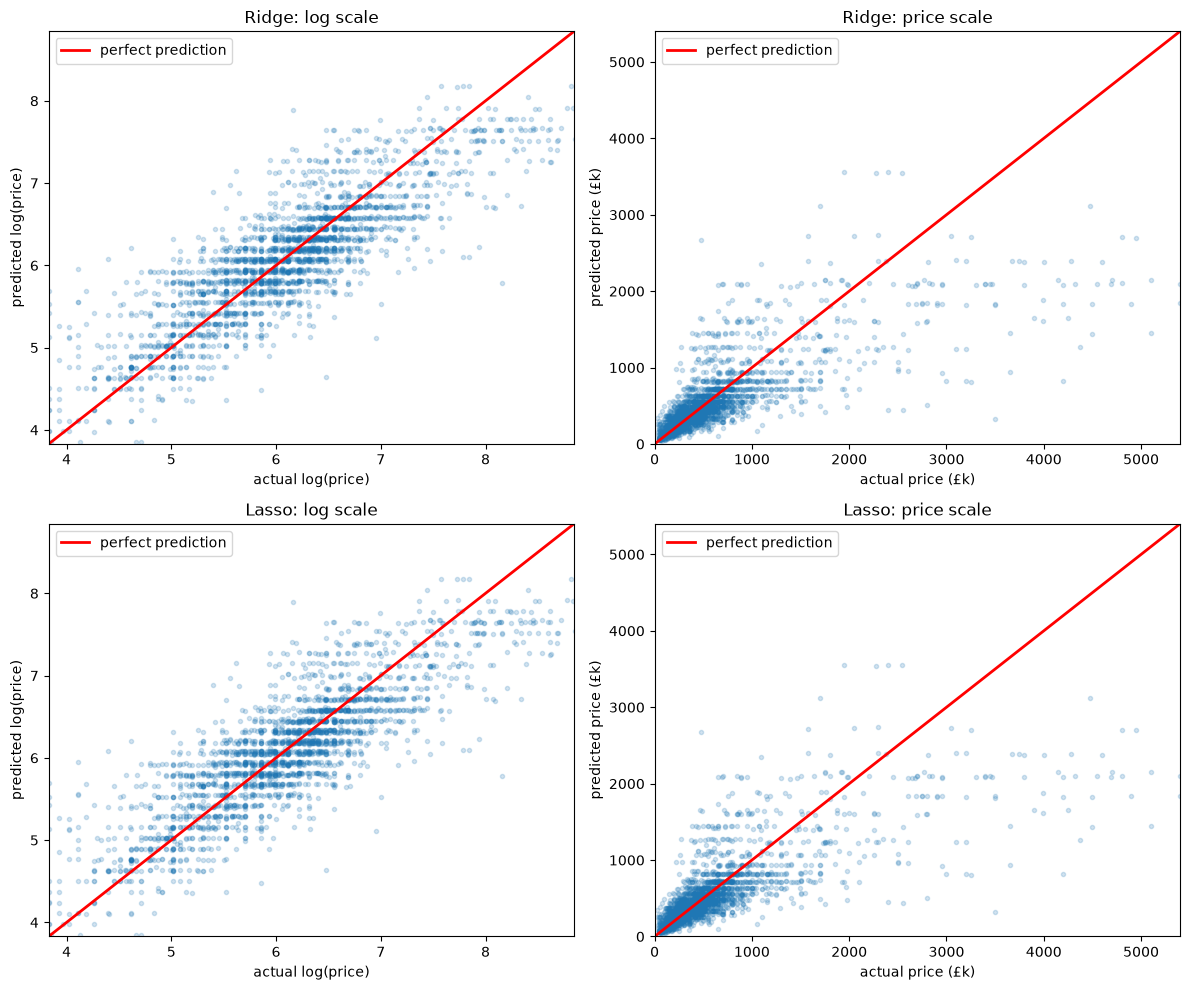

In [69]:
preds_log = {
    "Ridge": y_pred_log_ridge,
    "Lasso": y_pred_log_lasso,
}
y_true_log = np.ravel(ys_test)

fig, axes = plt.subplots(len(preds_log), 2, figsize=(12, 5 * len(preds_log)))

for row, (name, p_log) in zip(axes, preds_log.items()):
    p_log = np.ravel(p_log)
    pred, actual = np.expm1(p_log), np.expm1(y_true_log)

    # Left: log scale
    lo, hi = np.percentile(y_true_log, [0.5, 99.5])
    row[0].scatter(y_true_log, p_log, alpha=0.2, s=9)
    row[0].plot([lo, hi], [lo, hi], "r", lw=2, label="perfect prediction")
    row[0].set_xlim(lo, hi); row[0].set_ylim(lo, hi)
    row[0].set_xlabel("actual log(price)"); row[0].set_ylabel("predicted log(price)")
    row[0].set_title(f"{name}: log scale"); row[0].legend()

    # Right: price scale (£k)
    cap = np.percentile(actual, 99)
    row[1].scatter(actual, pred, alpha=0.2, s=9)
    row[1].plot([0, cap], [0, cap], "r", lw=2, label="perfect prediction")
    row[1].set_xlim(0, cap); row[1].set_ylim(0, cap)
    row[1].set_xlabel("actual price (£k)"); row[1].set_ylabel("predicted price (£k)")
    row[1].set_title(f"{name}: price scale"); row[1].legend()

plt.tight_layout()
plt.show()

## HistGradientBoostingRegressor

In [46]:
counts = clean['make'].value_counts()
rare = counts[counts < 10].index
clean['make'] = clean['make'].replace(dict.fromkeys(rare, 'Other')).astype('category')
print(clean['make'].nunique())

28


In [ ]:
from sklearn.ensemble import HistGradientBoostingRegressor

y = clean['log_price']
num_cols = ['year', 'km', 'fuel_Diesel', 'fuel_Electric', 'fuel_Hybrid', 'fuel_LPG',
            'fuel_Petrol', 'seller_Commercial Registration', 'seller_Corporate',
            'seller_Dealer', 'seller_Trustmark Dealer', 'transmiss_encoded']

X = clean[num_cols + ['make']]

Xs_train, Xs_test, ys_train, ys_test = train_test_split(X, y, test_size=0.2, random_state=42)

hgb = HistGradientBoostingRegressor(
    categorical_features='from_dtype',
    random_state=42
).fit(Xs_train, ys_train)

In [48]:
y_pred_log = hgb.predict(Xs_test)
pred, actual = np.expm1(y_pred_log), np.expm1(ys_test)

print("Train R2 (log)  ", hgb.score(Xs_train, ys_train))
print("Test R2 (log)   ", r2_score(ys_test, y_pred_log))
print("Test R2 (price) ", r2_score(actual, pred))
print("MAE (£k)        ", mean_absolute_error(actual, pred))
print("RMSE (£k)       ", np.sqrt(mean_squared_error(actual, pred)))

Train R2 (log)   0.8656883516780415
Test R2 (log)    0.8143877457275162
Test R2 (price)  0.4625649079647648
MAE (£k)         227.21981335259406
RMSE (£k)        1039.3772034777326


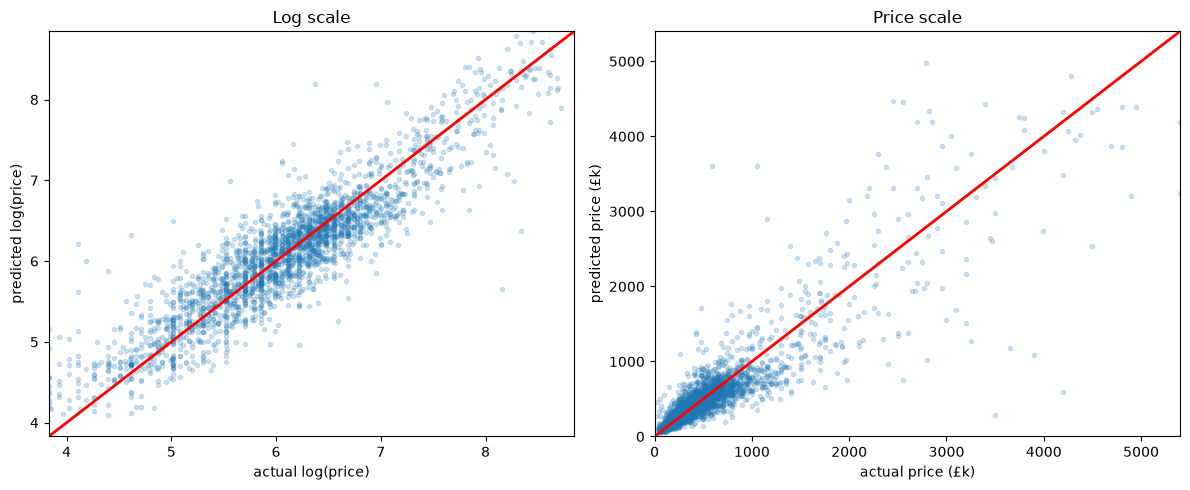

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

lo, hi = np.percentile(ys_test, [0.5, 99.5])
axes[0].scatter(ys_test, y_pred_log, alpha=0.2, s=9)
axes[0].plot([lo, hi], [lo, hi], "r", lw=2)
axes[0].set_xlim(lo, hi); axes[0].set_ylim(lo, hi)
axes[0].set_xlabel("actual log(price)"); axes[0].set_ylabel("predicted log(price)")
axes[0].set_title("Log scale")

cap = np.percentile(actual, 99)
axes[1].scatter(actual, pred, alpha=0.2, s=9)
axes[1].plot([0, cap], [0, cap], "r", lw=2)
axes[1].set_xlim(0, cap); axes[1].set_ylim(0, cap)
axes[1].set_xlabel("actual price (£k)"); axes[1].set_ylabel("predicted price (£k)")
axes[1].set_title("Price scale")

plt.tight_layout(); plt.show()

## Analysis
- No Significant difference in Error between different regression models (linear, ridge, lasso)
-This is because the benefit of using Ridge and Lasso is to correct for overfitting, but in this case the model is limited by bias as opposed to variance.
- This is due to observations >> features.  Recall, approximately 12k observations

- Standard regression models R^2 on the order of 0.7
The car make and model columns weren't used for standard regression.  Important feature was dropped.
make and model are highly cardinalised columns that require a significant clean up.

- Chose to clean only make
Employed an ensemble method, HistGradientBoostingRegressor in order to leverage the car make. 
An improvement to R^2 of 0.8 was observed

- Another possible option would be to use a subset of the data which has additional features such as engine, max power, torque and age.

